# L1.2 - budowa bazy treningowej i augmentacja

Zdjęcie lotnicze lub scena satelitarna ma tysiące pikseli w każdym wymiarze, a sieć przyjmuje małe obrazy o stałym rozmiarze (np. 128×128). Między jednym a drugim stoi **przygotowanie bazy treningowej**:

1. dopasowanie obrazu i danych referencyjnych,
2. pocięcie na kafle z pokryciem i indeksem,
3. zapis na dysk w uporządkowanej strukturze,
4. podział na zbiory treningowy, walidacyjny i testowy,
5. augmentacja.

Podawanie kafli do sieci (`Dataset`, `DataLoader`) omówimy na zajęciach z klasyfikacji.

Pracujemy na zdjęciu `lot1.tif` i mapie referencyjnej `lot1true6.tif` (6 klas pokrycia terenu) - do tych danych wrócimy w L6.

In [1]:
import shutil
import warnings
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import rasterio
from rasterio.windows import Window
import torch
import albumentations as A
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)
DANE = Path("dane")
BAZA = Path("baza")           # tu powstanie baza treningowa
print("albumentations", A.__version__, "| torch", torch.__version__)

albumentations 2.0.8 | torch 2.14.1+cpu


## 1. Obraz i dane referencyjne

obraz:       (625, 876, 3)
referencja:  (640, 896, 3)


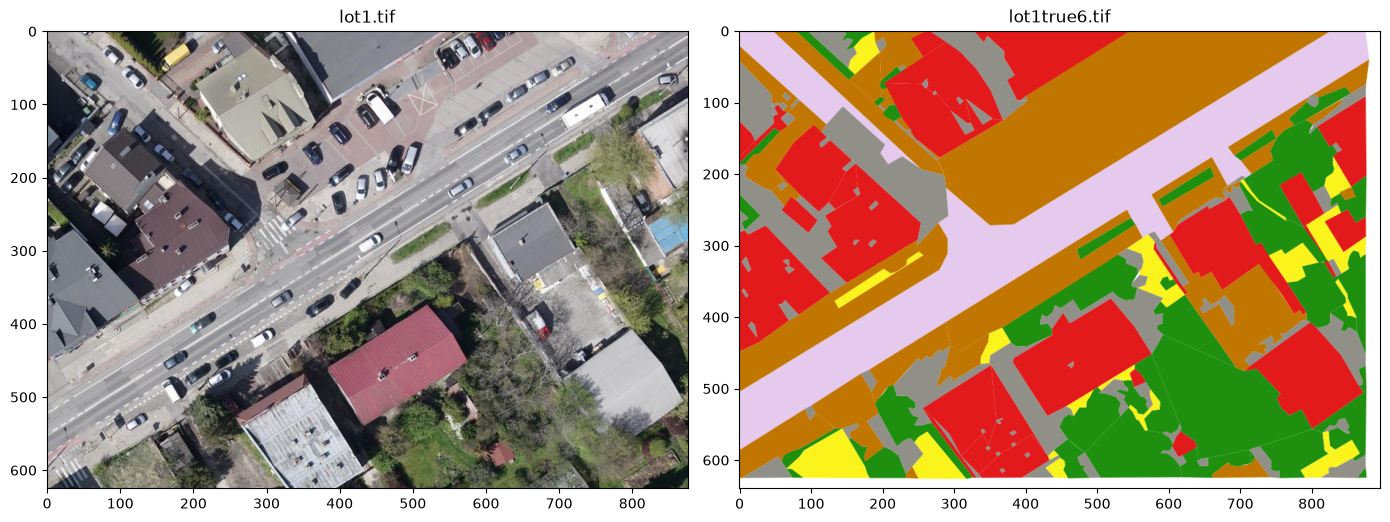

In [2]:
img = np.array(Image.open(DANE / "lot1.tif").convert("RGB"))
ref = np.array(Image.open(DANE / "lot1true6.tif").convert("RGB"))
print("obraz:      ", img.shape)
print("referencja: ", ref.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(img); axes[0].set_title("lot1.tif")
axes[1].imshow(ref); axes[1].set_title("lot1true6.tif")
plt.tight_layout(); plt.show()

### Kontrola zgodności

Rozmiary się różnią. Zanim cokolwiek potniemy, trzeba ustalić dlaczego - przesunięta o kilkanaście pikseli maska oznacza błędne etykiety w całej bazie, a sieć nauczy się tych błędów.

In [3]:
bialy = (ref == 255).all(axis=-1)
print("białe wiersze na dole:  ", int((bialy.mean(axis=1) > 0.9).sum()))
print("białe kolumny z prawej: ", int((bialy.mean(axis=0) > 0.9).sum()))

białe wiersze na dole:   14
białe kolumny z prawej:  18


Referencja to ten sam obszar uzupełniony białym marginesem z prawej i u dołu, więc wystarczy przyciąć ją do rozmiaru obrazu, licząc od lewego górnego rogu. Poprawność sprawdzamy wizualnie, nakładając półprzezroczystą referencję na obraz.

W danych z pełną georeferencją dopasowanie wykonuje się po współrzędnych (np. `rasterio.windows.from_bounds`), nie po indeksach pikseli.

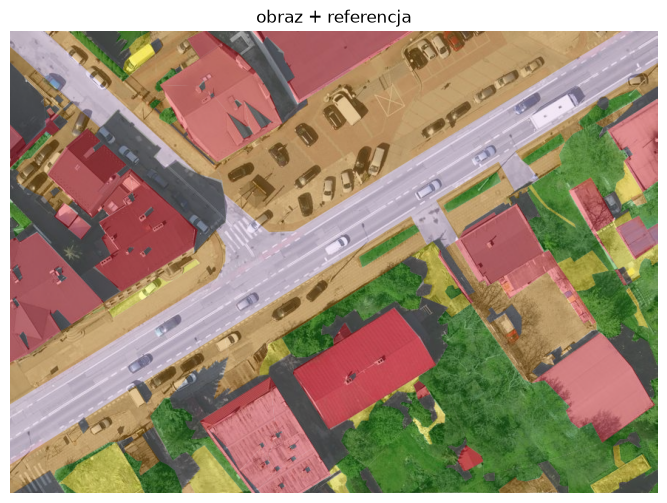

In [4]:
H, W = img.shape[:2]
ref = ref[:H, :W]

nalozenie = (0.6 * img + 0.4 * ref).astype(np.uint8)
plt.figure(figsize=(10, 6)); plt.imshow(nalozenie); plt.axis("off"); plt.title("obraz + referencja"); plt.show()

### Z kolorów na numery klas

Sieć potrzebuje maski, w której każdy piksel ma **numer klasy** (0–5), a nie kolor RGB.

In [5]:
KLASY = {
    0: ("asfalt",      (229, 202, 237)),
    1: ("beton",       (192, 118, 0)),
    2: ("cienie",      (145, 144, 136)),
    3: ("grunt",       (251, 244, 28)),
    4: ("roslinnosc",  (31, 143, 16)),
    5: ("zabudowa",    (227, 26, 28)),
}
NAZWY = [n for n, _ in KLASY.values()]
PALETA = np.array([k for _, k in KLASY.values()], dtype=np.uint8)
IGNORUJ = 255       # piksele bez pewnej etykiety

kolory, licznosc = np.unique(ref.reshape(-1, 3), axis=0, return_counts=True)
print("liczba różnych kolorów w referencji:", len(kolory), "(powinno być 6)")

liczba różnych kolorów w referencji: 6650 (powinno być 6)


Kolorów jest kilka tysięcy zamiast sześciu: referencję zapisano lub przeskalowano z interpolacją i na granicach klas powstały kolory pośrednie (por. L1.1, „maski skalujemy metodą najbliższego sąsiada”). Dokładne porównanie kolorów zgubiłoby te piksele.

Rozwiązanie: każdemu pikselowi przypisujemy klasę o **najbliższym** kolorze, a piksele zbyt odległe od wszystkich kolorów palety oznaczamy jako `IGNORUJ` - funkcja straty będzie je pomijać (`CrossEntropyLoss(ignore_index=255)`).

wartości w masce: [  0   1   2   3   4   5 255]
piksele ignorowane: 2.0%


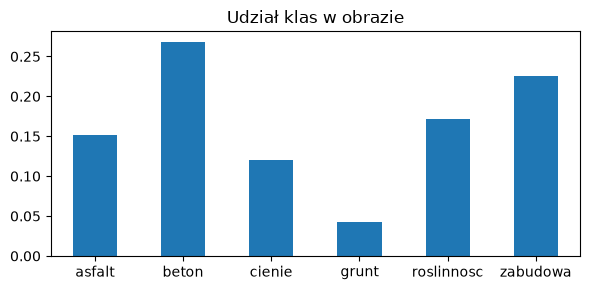

In [14]:
def kolory_na_klasy(ref_rgb, paleta, prog=60, ignoruj=IGNORUJ):
    # odległość każdego piksela od każdego koloru palety: tablica (H, W, liczba_klas)
    odl = np.abs(ref_rgb[:, :, None, :].astype(np.int32) - paleta[None, None].astype(np.int32)).sum(axis=-1)
    klasy = odl.argmin(axis=-1).astype(np.uint8)
    klasy[odl.min(axis=-1) > prog] = ignoruj
    return klasy

maska = kolory_na_klasy(ref, PALETA)
print("wartości w masce:", np.unique(maska))
print(f"piksele ignorowane: {(maska == IGNORUJ).mean():.1%}")

udzial = pd.Series({NAZWY[k]: (maska == k).mean() for k in range(6)})
udzial.plot.bar(figsize=(6, 3), title="Udział klas w obrazie", rot=0); plt.tight_layout(); plt.show()

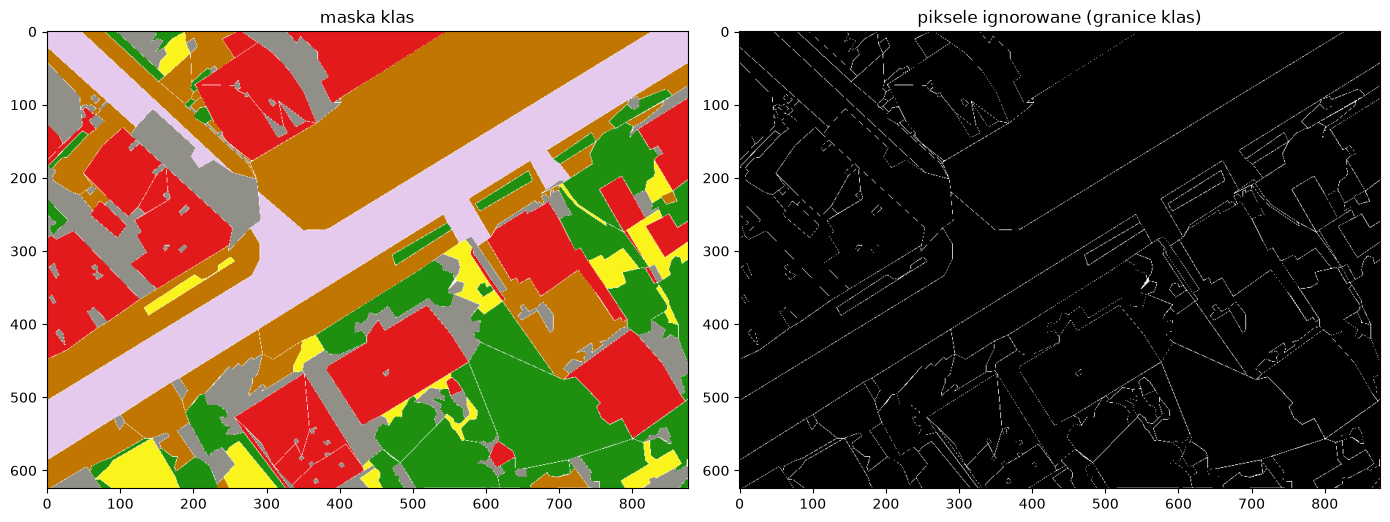

In [15]:
def koloruj(maska):
    # Maska klas -> obraz RGB do wyświetlenia (ignorowane na biało).
    rgb = np.full((*maska.shape, 3), 255, dtype=np.uint8)
    for k in range(len(PALETA)):
        rgb[maska == k] = PALETA[k]
    return rgb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(koloruj(maska)); axes[0].set_title("maska klas")
axes[1].imshow(maska == IGNORUJ, cmap="gray"); axes[1].set_title("piksele ignorowane (granice klas)")
plt.tight_layout(); plt.show()

## 2. Cięcie na kafle

Pokażemy cięcie w takiej postaci, w jakiej działa w rzeczywistych narzędziach do detekcji obiektów na zobrazowaniach satelitarnych: **kafle o stałym rozmiarze, z wzajemnym pokryciem, indeksowane numerem kolumny i wiersza siatki**, a obok nich obraz całej sceny z naniesionym położeniem kafli.

| Parametr | Znaczenie | Kompromis |
| --- | --- | --- |
| `tile_size` | bok kafla w pikselach | większy = więcej kontekstu, ale mniej próbek i więcej pamięci |
| `overlap` | pokrycie sąsiednich kafli w pikselach | krok siatki = `tile_size - overlap` |
| `pad_value` | wartość dopełnienia, gdy okno wychodzi poza obraz | potrzebne tylko, gdy obraz jest mniejszy od kafla |

### Po co pokrycie?

Obiekt leżący na granicy kafli zostałby przecięty i żaden kafel nie zawierałby go w całości. Pokrycie większe od rozmiaru typowego obiektu gwarantuje, że każdy obiekt jest cały w co najmniej jednym kaflu. Ceną są **duplikaty**: ten sam obiekt wykryty w dwóch kaflach trzeba potem scalić (NMS - wrócimy do tego przy YOLO).

### Siatka

Początki kafli wyznaczamy co `tile_size - overlap` pikseli. Jeśli ostatni kafel nie sięga krawędzi, dodajemy jeszcze jeden, **dosunięty do krawędzi** - nie tracimy danych i nie wprowadzamy sztucznych pikseli, ale ostatnia kolumna i wiersz mają większe pokrycie niż pozostałe.

In [17]:
def siatka(width, height, tile_size, overlap, brzegi="dosun"):
    # Początki kafli w osi x i y.
    # brzegi="dosun":  ostatni kafel dosunięty do krawędzi,
    # brzegi="odrzuc": niepełne kafle przy krawędzi są pomijane.
    stride = tile_size - overlap
    x_starts = list(range(0, max(width - tile_size + 1, 1), stride))
    y_starts = list(range(0, max(height - tile_size + 1, 1), stride))
    if brzegi == "dosun":
        if x_starts[-1] + tile_size < width:
            x_starts.append(max(width - tile_size, 0))       # ostatnia kolumna dosunięta do prawej krawędzi
        if y_starts[-1] + tile_size < height:
            y_starts.append(max(height - tile_size, 0))      # ostatni wiersz dosunięty do dolnej krawędzi
    return x_starts, y_starts

x_starts, y_starts = siatka(W, H, tile_size=144, overlap=24)
print("krok siatki:", 128 - 32)
print("x:", x_starts)
print("y:", y_starts)

krok siatki: 96
x: [0, 120, 240, 360, 480, 600, 720, 732]
y: [0, 120, 240, 360, 480, 481]


Zwróć uwagę na ostatnie wartości: nie są wielokrotnością kroku.

### Indeksowanie kafli

Każdy kafel dostaje **indeks kolumny i wiersza liczony od 1** oraz nazwę pliku `{kolumna}_{wiersz}_{nazwa_sceny}.png`. Opis kafla przechowujemy w niemodyfikowalnej strukturze `TileInfo`.

In [18]:
@dataclass(frozen=True)
class TileInfo:
    col_idx: int      # indeks kolumny siatki (od 1)
    row_idx: int      # indeks wiersza siatki (od 1)
    x0: int           # lewy górny róg kafla w pikselach sceny
    y0: int
    read_w: int       # faktycznie odczytana szerokość i wysokość (przed dopełnieniem)
    read_h: int
    out_name: str     # nazwa pliku kafla


def lista_kafli(base_name, width, height, tile_size, overlap, brzegi="dosun"):
    # Lista opisów wszystkich kafli sceny (odpowiednik GeoTiffTiler._make_jobs).
    if not (0 <= overlap < tile_size):
        raise ValueError("overlap musi spełniać 0 <= overlap < tile_size")
    x_starts, y_starts = siatka(width, height, tile_size, overlap, brzegi)
    kafle = []
    for row_idx, y0 in enumerate(y_starts, start=1):
        read_h = min(tile_size, height - y0)
        for col_idx, x0 in enumerate(x_starts, start=1):
            read_w = min(tile_size, width - x0)
            kafle.append(TileInfo(col_idx, row_idx, x0, y0, read_w, read_h,
                                  out_name=f"{col_idx}_{row_idx}_{base_name}.png"))
    return kafle


def dopelnij(kafel, tile_size, pad_value=0):
    # Dopełnia kafel (H, W) lub (H, W, C) do pełnego rozmiaru wartością pad_value.
    h, w = kafel.shape[:2]
    if h == tile_size and w == tile_size:
        return kafel
    pelny = np.full((tile_size, tile_size, *kafel.shape[2:]), pad_value, dtype=kafel.dtype)
    pelny[:h, :w] = kafel
    return pelny


kafle = lista_kafli("lot1", W, H, tile_size=128, overlap=32)
print("liczba kafli:", len(kafle))
kafle[0], kafle[-1]

liczba kafli: 63


(TileInfo(col_idx=1, row_idx=1, x0=0, y0=0, read_w=128, read_h=128, out_name='1_1_lot1.png'),
 TileInfo(col_idx=9, row_idx=7, x0=748, y0=497, read_w=128, read_h=128, out_name='9_7_lot1.png'))

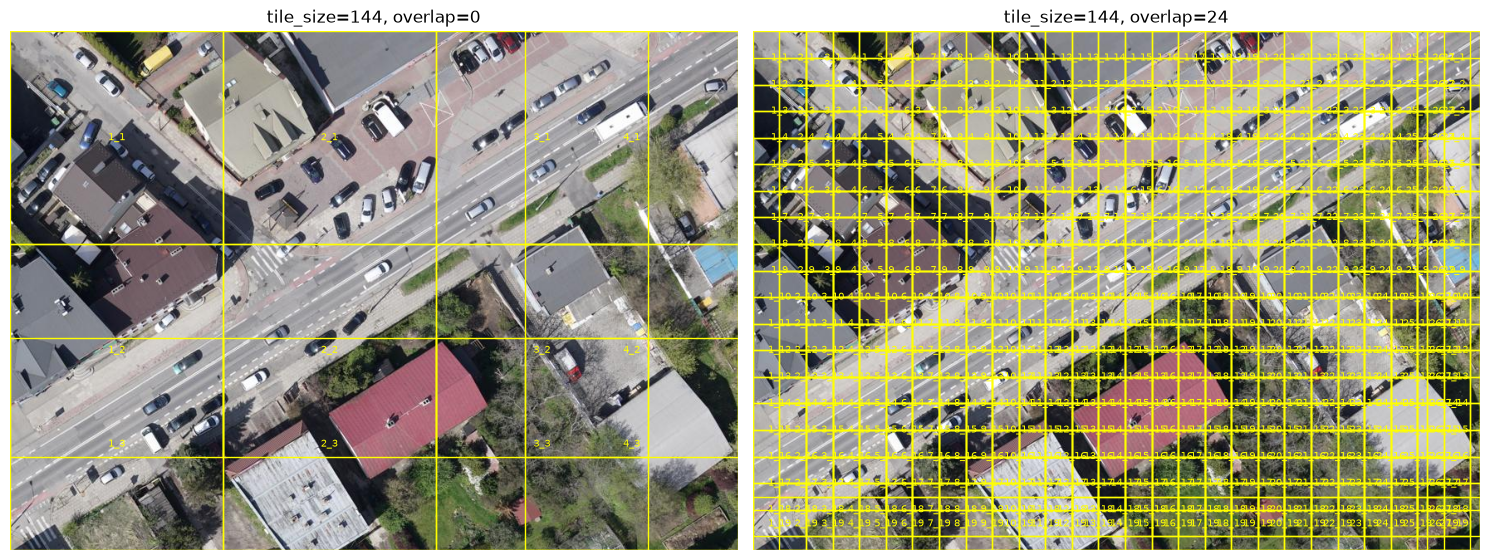

In [22]:
def rysuj_siatke(ax, obraz, kafle, kolory=None, etykiety=True, tytul="", skala=1.0):
    # Rysuje ramki kafli (lista TileInfo) na obrazie; skala < 1, gdy obraz jest pomniejszonym podglądem.
    ax.imshow(obraz, cmap="gray" if obraz.ndim == 2 else None)
    for i, k in enumerate(kafle):
        kolor = kolory[i] if kolory is not None else "yellow"
        ax.add_patch(patches.Rectangle((k.x0 * skala, k.y0 * skala), k.read_w * skala, k.read_h * skala,
                                       fill=False, edgecolor=kolor, linewidth=1))
        if etykiety:
            ax.text((k.x0 + k.read_w / 2) * skala, (k.y0 + k.read_h / 2) * skala, f"{k.col_idx}_{k.row_idx}",
                    color=kolor, fontsize=7, ha="center", va="center")
    ax.set_title(tytul); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
rysuj_siatke(axes[0], img, lista_kafli("lot1", W, H, 256, 0), tytul="tile_size=144, overlap=0")
rysuj_siatke(axes[1], img, lista_kafli("lot1", W, H, 64, 32), tytul="tile_size=144, overlap=24")
plt.tight_layout(); plt.show()

In [24]:
for tile_size, overlap in [(256, 0), (256, 32), (256, 64), (64, 32)]:
    n = len(lista_kafli("lot1", W, H, tile_size, overlap))
    print(f"tile_size={tile_size:3d} overlap={overlap:2d} krok={tile_size - overlap:3d} -> {n:4d} kafli")

tile_size=256 overlap= 0 krok=256 ->   12 kafli
tile_size=256 overlap=32 krok=224 ->   12 kafli
tile_size=256 overlap=64 krok=192 ->   15 kafli
tile_size= 64 overlap=32 krok= 32 ->  513 kafli


### Trzy produkty cięcia sceny

Narzędzia przygotowujące dane do etykietowania i detekcji tworzą zwykle dla każdej sceny osobny katalog z trzema produktami:

```
kafle/
    <nazwa_sceny>/
        tiles/                           a) kafle: {kolumna}_{wiersz}_{nazwa_sceny}.png
        8bit_nogeoref_<nazwa_sceny>.png  b) cała scena w wersji 8-bitowej, bez georeferencji
        num_tiles_<nazwa_sceny>.png      c) scena z naniesionymi ramkami i indeksami kafli
        indeks.csv                       pozycja każdego kafla w pikselach sceny
```

- **a)** to dane dla sieci (lub dla osoby etykietującej),
- **b)** to podgląd, który otworzy każda przeglądarka obrazów - oryginalna scena bywa 16-bitowa i ma kilka gigabajtów,
- **c)** to **mapa kafli**: pozwala odnaleźć kafel `5_3` na scenie i odwrotnie, wskazać kafle zawierające interesujący obszar.

Kafle całkowicie puste (same zera lub same wartości 255, np. poza zasięgiem zobrazowania) są pomijane.

Obraz o większej głębi bitowej zamieniamy na 8 bitów z obcięciem najjaśniejszych wartości na poziomie trzykrotnej średniej - pojedyncze silne odbicia nie „zgniatają” wtedy reszty obrazu w ciemne tony (por. rozciąganie percentylowe w L1.1).

In [25]:
def do_8bit(obraz):
    # Zamiana obrazu na 8 bitów; jasne wartości obcinane na poziomie 3 x średnia.
    if obraz.dtype == np.uint8:
        return obraz
    obraz = obraz.astype(np.float32)
    gora = min(float(obraz.max()), 3 * float(obraz.mean()))
    return (np.clip(obraz, 0, gora) / gora * 255).astype(np.uint8)


def obraz_z_siatka(img8, kafle, kolor=(0, 255, 0)):
    # Produkt c): kopia sceny z ramkami kafli i indeksami kolumna_wiersz.
    plan = img8.copy()
    if plan.ndim == 2:
        plan = cv2.cvtColor(plan, cv2.COLOR_GRAY2RGB)
    rozmiar = kafle[0].read_w
    font, skala, grubosc = cv2.FONT_HERSHEY_PLAIN, rozmiar / 160, max(1, rozmiar // 320)
    for k in kafle:
        cv2.rectangle(plan, (k.x0, k.y0), (k.x0 + k.read_w, k.y0 + k.read_h), kolor, grubosc)
        tekst = f"{k.col_idx}_{k.row_idx}"
        (tw, th), _ = cv2.getTextSize(tekst, font, skala, grubosc)
        srodek = (k.x0 + (k.read_w - tw) // 2, k.y0 + (k.read_h + th) // 2)
        cv2.putText(plan, tekst, srodek, font, skala, kolor, grubosc, cv2.LINE_AA)
    return plan


def potnij_scene(sciezka, katalog, tile_size=640, overlap=100, brzegi="dosun", pad_value=0):
    # Tnie scenę na kafle i zapisuje trzy produkty oraz indeks. Zwraca katalog sceny i tabelę indeksu.
    sciezka = Path(sciezka)
    nazwa = sciezka.stem
    kat = Path(katalog) / nazwa
    shutil.rmtree(kat, ignore_errors=True)
    (kat / "tiles").mkdir(parents=True, exist_ok=True)

    with rasterio.open(sciezka) as src:
        obraz = src.read()                                    # (C, H, W)
    obraz = obraz[0] if obraz.shape[0] == 1 else np.transpose(obraz[:3], (1, 2, 0))
    img8 = do_8bit(obraz)
    wys, szer = img8.shape[:2]
    Image.fromarray(img8).save(kat / f"8bit_nogeoref_{nazwa}.png")                    # produkt b)

    zapisane, wiersze = [], []
    for k in lista_kafli(nazwa, szer, wys, tile_size, overlap, brzegi):
        kafel = dopelnij(img8[k.y0:k.y0 + k.read_h, k.x0:k.x0 + k.read_w], tile_size, pad_value)
        if kafel.mean() in (0, 255):                          # kafel pusty - pomijamy
            continue
        Image.fromarray(kafel).save(kat / "tiles" / k.out_name)                       # produkt a)
        zapisane.append(k)
        wiersze.append({**asdict(k), "srednia": round(float(kafel.mean()), 2)})

    Image.fromarray(obraz_z_siatka(img8, zapisane)).save(kat / f"num_tiles_{nazwa}.png")   # produkt c)
    indeks = pd.DataFrame(wiersze)
    indeks.to_csv(kat / "indeks.csv", index=False)
    print(f"{nazwa}: scena {szer}x{wys}, zapisano {len(zapisane)} kafli {tile_size}x{tile_size} (pokrycie {overlap}) -> {kat}")
    return kat, indeks

lot1: scena 876x625, zapisano 63 kafli 128x128 (pokrycie 32) -> kafle\lot1

Zawartość katalogu sceny:
   8bit_nogeoref_lot1.png 
   indeks.csv 
   num_tiles_lot1.png 
   tiles (katalog, 63 plików)


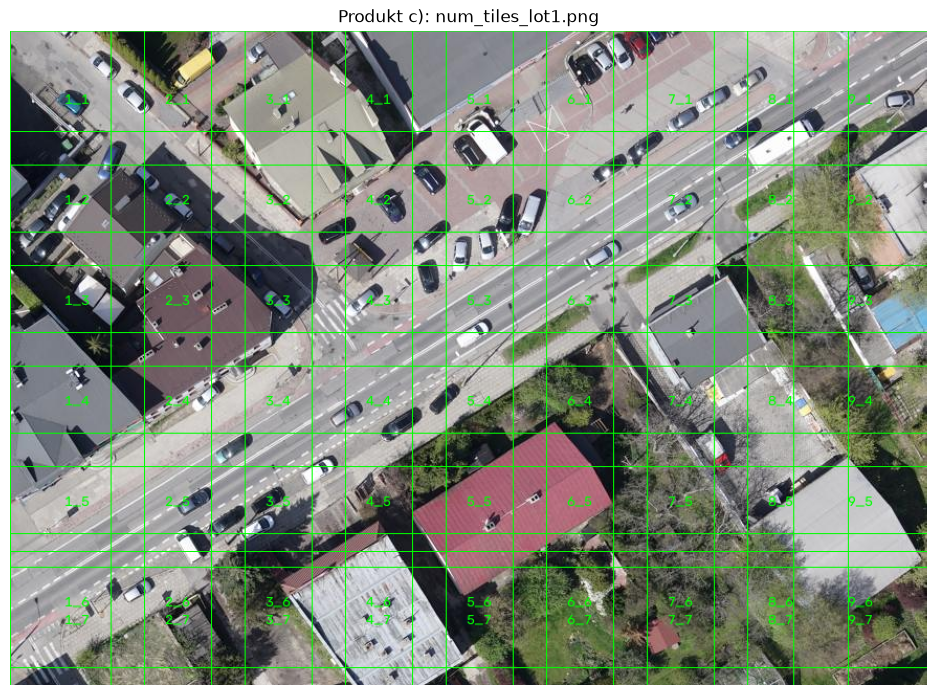

,col_idx,row_idx,x0,y0,read_w,read_h,out_name,srednia
0,1,1,0,0,128,128,1_1_lot1.png,121.37
1,2,1,96,0,128,128,2_1_lot1.png,128.78
2,3,1,192,0,128,128,3_1_lot1.png,144.98
3,4,1,288,0,128,128,4_1_lot1.png,120.69
4,5,1,384,0,128,128,5_1_lot1.png,149.31


In [67]:
kat_lot1, indeks_lot1 = potnij_scene(DANE / "lot1.tif", "kafle", tile_size=128, overlap=32)

print("\nZawartość katalogu sceny:")
for p in sorted(kat_lot1.iterdir()):
    print("  ", p.name, "(katalog, %d plików)" % len(list(p.iterdir())) if p.is_dir() else "")

plt.figure(figsize=(12, 8.5))
plt.imshow(Image.open(kat_lot1 / "num_tiles_lot1.png")); plt.axis("off"); plt.title("Produkt c): num_tiles_lot1.png")
plt.show()
indeks_lot1.head()

Brzegi można też potraktować inaczej: **odrzucić** niepełne kafle zamiast dosuwać ostatni do krawędzi. Parametr `brzegi="odrzuc"` włącza to zachowanie - pas przy prawej i dolnej krawędzi sceny nie trafia wtedy do żadnego kafla.

In [29]:
for brzegi in ["dosun", "odrzuc"]:
    k = lista_kafli("lot1", W, H, 256, 32, brzegi)
    print(f"brzegi={brzegi:7s} -> {len(k):3d} kafli, ostatni kafel kończy się na x={k[-1].x0 + 128} (szerokość {W}), y={k[-1].y0 + 128} (wysokość {H})")

brzegi=dosun   ->  12 kafli, ostatni kafel kończy się na x=748 (szerokość 876), y=497 (wysokość 625)
brzegi=odrzuc  ->   6 kafli, ostatni kafel kończy się na x=576 (szerokość 876), y=352 (wysokość 625)


**Zadanie 1.** Ile kafli 256×256 z pokryciem 128 powstanie ze sceny 10 980×10 980 px (jeden kanał Sentinel-2 w rozdzielczości 10 m)? Ile miejsca zajmą jako nieskompresowane `uint16` przy 4 kanałach? Policz funkcją `lista_kafli`.

In [30]:
n = len(lista_kafli("S2", 10980, 10980, 256, 128))
gb = n * 256 * 256 * 4 * 2 / 1024**3
print(f"{n} kafli, {gb:.1f} GB")

7225 kafli, 3.5 GB


## 3. Zapis bazy na dysk

Zasady:

- obraz i maska kafla mają **tę samą nazwę** w osobnych katalogach,
- nazwa zawiera indeks kafla i nazwę sceny (`6_5_lot1.png`),
- obok powstaje **tabela indeksu** z pozycją każdego kafla (`x0`, `y0`), udziałem klas i klasą dominującą - dzięki niej kafel da się odnaleźć na oryginale, a wyniki z kafli złożyć z powrotem w mapę,
- format **bezstratny** (PNG, TIFF). JPEG zmienia wartości pikseli, więc dla masek jest niedopuszczalny.

Bazę budujemy z kafli 128×128 z pokryciem 64 (krok 64).

In [31]:
ROZMIAR, POKRYCIE = 128, 64

# Zaczynamy od czystego katalogu. ignore_errors: w folderze synchronizowanym (OneDrive)
# system bywa zajęty plikami i usuwanie potrafi zgłosić błąd dostępu.
shutil.rmtree(BAZA, ignore_errors=True)
(BAZA / "images").mkdir(parents=True, exist_ok=True)
(BAZA / "masks").mkdir(parents=True, exist_ok=True)

wiersze = []
for k in lista_kafli("lot1", W, H, ROZMIAR, POKRYCIE):
    okno = (slice(k.y0, k.y0 + k.read_h), slice(k.x0, k.x0 + k.read_w))
    kafel = dopelnij(img[okno], ROZMIAR, pad_value=0)
    kafel_maska = dopelnij(maska[okno], ROZMIAR, pad_value=IGNORUJ)     # dopełnienie maski: "ignoruj", nie klasa 0
    Image.fromarray(kafel).save(BAZA / "images" / k.out_name)
    Image.fromarray(kafel_maska).save(BAZA / "masks" / k.out_name)

    udzialy = {n: float((kafel_maska == i).mean()) for i, n in enumerate(NAZWY)}
    wiersze.append({"plik": k.out_name, "col": k.col_idx, "row": k.row_idx, "x0": k.x0, "y0": k.y0,
                    **udzialy, "dominujaca": max(udzialy, key=udzialy.get)})

meta = pd.DataFrame(wiersze)
meta.to_csv(BAZA / "indeks.csv", index=False)
print("zapisano kafli:", len(meta))
meta.head()

zapisano kafli: 117


,plik,col,row,x0,y0,asfalt,beton,cienie,grunt,roslinnosc,zabudowa,dominujaca
0,1_1_lot1.png,1,1,0,0,0.420532,0.273315,0.233643,0.000000,0.035522,0.013855,asfalt
1,2_1_lot1.png,2,1,64,0,0.293945,0.365173,0.143860,0.076477,0.090637,0.000305,beton
2,3_1_lot1.png,3,1,128,0,0.058167,0.420715,0.112488,0.078125,0.096069,0.199951,beton
3,4_1_lot1.png,4,1,192,0,0.000000,0.224731,0.090393,0.001648,0.040955,0.614319,zabudowa
4,5_1_lot1.png,5,1,256,0,0.000000,0.008179,0.348206,0.000000,0.000000,0.624634,zabudowa


identyczna po odczycie: True | wartości: [  0   1   2   4   5 255]


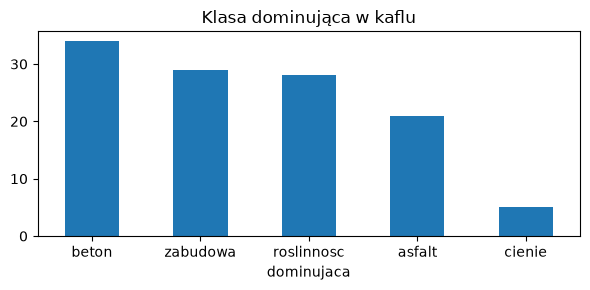

In [104]:
# Kontrola: czy maska po zapisie i odczycie jest identyczna?
p = meta.plik[0]
odczyt = np.array(Image.open(BAZA / "masks" / p))
print("identyczna po odczycie:", np.array_equal(odczyt, maska[:ROZMIAR, :ROZMIAR]), "| wartości:", np.unique(odczyt))

meta["dominujaca"].value_counts().plot.bar(figsize=(6, 3), rot=0, title="Klasa dominująca w kaflu")
plt.tight_layout(); plt.show()

Baza jest **niezbalansowana**: kafli z dominującym gruntem jest kilka, z zabudową kilkadziesiąt. To typowe dla danych przestrzennych i trzeba o tym pamiętać przy podziale na zbiory i przy ocenie modelu (L6: accuracy a kappa i IoU).

## 4. Podział na zbiory

### Podział losowy - i dlaczego jest tu błędem

In [32]:
train_l, reszta = train_test_split(meta, test_size=0.4, random_state=42)
val_l, test_l = train_test_split(reszta, test_size=0.5, random_state=42)

def nakladajace_sie(a, b, rozmiar):
    # Ile kafli ze zbioru b ma wspólne piksele z jakimkolwiek kaflem ze zbioru a?
    dy = np.abs(b.y0.values[:, None] - a.y0.values[None, :])
    dx = np.abs(b.x0.values[:, None] - a.x0.values[None, :])
    return int(((dy < rozmiar) & (dx < rozmiar)).any(axis=1).sum())

print(f"train={len(train_l)}  val={len(val_l)}  test={len(test_l)}")
print(f"kafle walidacyjne nakładające się na treningowe: {nakladajace_sie(train_l, val_l, ROZMIAR)} z {len(val_l)}")
print(f"kafle testowe nakładające się na treningowe:     {nakladajace_sie(train_l, test_l, ROZMIAR)} z {len(test_l)}")

train=70  val=23  test=24
kafle walidacyjne nakładające się na treningowe: 23 z 23
kafle testowe nakładające się na treningowe:     24 z 24


Przy pokryciu 50% niemal każdy kafel walidacyjny i testowy zawiera piksele, które sieć widziała w treningu. To **wyciek danych**: wynik na teście będzie zawyżony i nic nie powie o działaniu modelu na nowym obszarze. Nawet bez pokrycia sąsiednie kafle są do siebie bardzo podobne (autokorelacja przestrzenna).

### Podział przestrzenny

Dzielimy **obszar**, nie kafle: lewa część obrazu to trening, środkowy pas walidacja, prawy pas test. Kafle przecinające granicę odrzucamy.

zbior
train        63
odrzucony    18
val          18
test         18
Name: count, dtype: int64


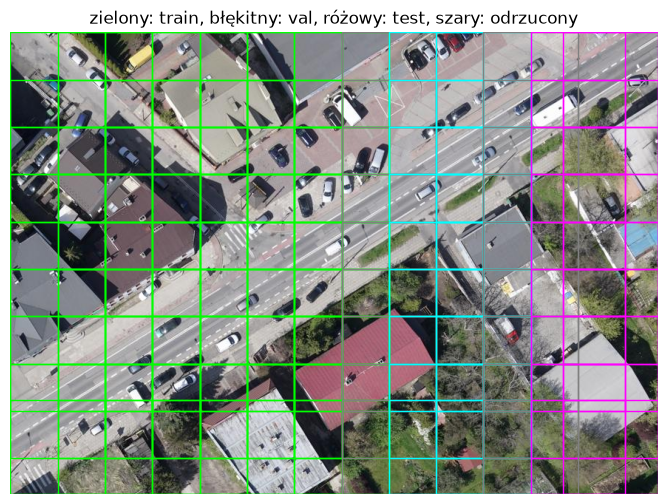

In [33]:
G1, G2 = 512, 704          # granice w pikselach (oś x): train | val | test

def przydziel(x, rozmiar=ROZMIAR):
    if x + rozmiar <= G1:
        return "train"
    if x >= G1 and x + rozmiar <= G2:
        return "val"
    if x >= G2:
        return "test"
    return "odrzucony"      # kafel przecina granicę

meta["zbior"] = meta.x0.apply(przydziel)
print(meta.zbior.value_counts())

mapa_kolorow = {"train": "lime", "val": "cyan", "test": "magenta", "odrzucony": "gray"}
fig, ax = plt.subplots(figsize=(11, 6))
rysuj_siatke(ax, img, lista_kafli("lot1", W, H, ROZMIAR, POKRYCIE), kolory=[mapa_kolorow[z] for z in meta.zbior],
             etykiety=False, tytul="zielony: train, błękitny: val, różowy: test, szary: odrzucony")
plt.show()

nakładanie train-val:  0
nakładanie train-test: 0


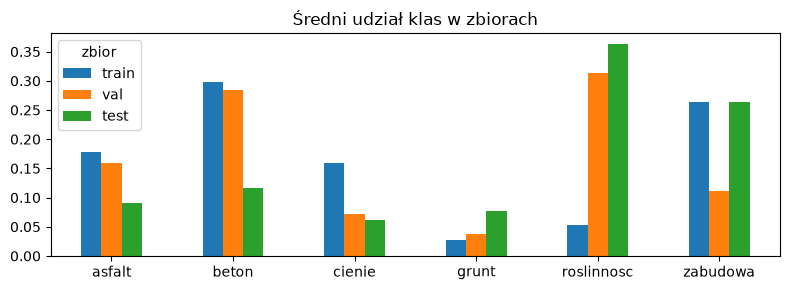

,asfalt,beton,cienie,grunt,roslinnosc,zabudowa
zbior,,,,,,
train,0.179,0.298,0.159,0.028,0.053,0.264
val,0.160,0.284,0.072,0.038,0.314,0.112
test,0.091,0.117,0.062,0.078,0.363,0.264


In [34]:
tr, va, te = (meta[meta.zbior == z] for z in ["train", "val", "test"])
print("nakładanie train-val: ", nakladajace_sie(tr, va, ROZMIAR))
print("nakładanie train-test:", nakladajace_sie(tr, te, ROZMIAR))

# Czy każda klasa występuje w każdym zbiorze?
sklad = meta[meta.zbior != "odrzucony"].groupby("zbior")[NAZWY].mean().loc[["train", "val", "test"]]
sklad.T.plot.bar(figsize=(8, 3), rot=0, title="Średni udział klas w zbiorach"); plt.tight_layout(); plt.show()
sklad.round(3)

Podział przestrzenny ma swoją cenę: rozkład klas w zbiorach różni się (np. grunt występuje głównie w jednej części obrazu). Przy prawdziwych danych stosuje się kilka rozłącznych obszarów lub osobne sceny na test - w L6 taką rolę może pełnić `lot2.tif`.

## 5. Augmentacja

Augmentacja to losowe przekształcenia obrazu treningowego, po których **etykieta pozostaje prawdziwa**. Sieć w każdej epoce widzi inną wersję tego samego kafla, co ogranicza przeuczenie - szczególnie ważne, gdy danych jest mało (u nas kilkadziesiąt kafli).

| Rodzaj | Przykłady | Maska |
| --- | --- | --- |
| geometryczna | odbicia, obroty, przesunięcie, skala | musi być przekształcona **identycznie** |
| fotometryczna | jasność, kontrast, szum, rozmycie | pozostaje **bez zmian** |

Używamy biblioteki **albumentations**, która przekształca obraz i maskę (oraz ramki obiektów) jednym wywołaniem.

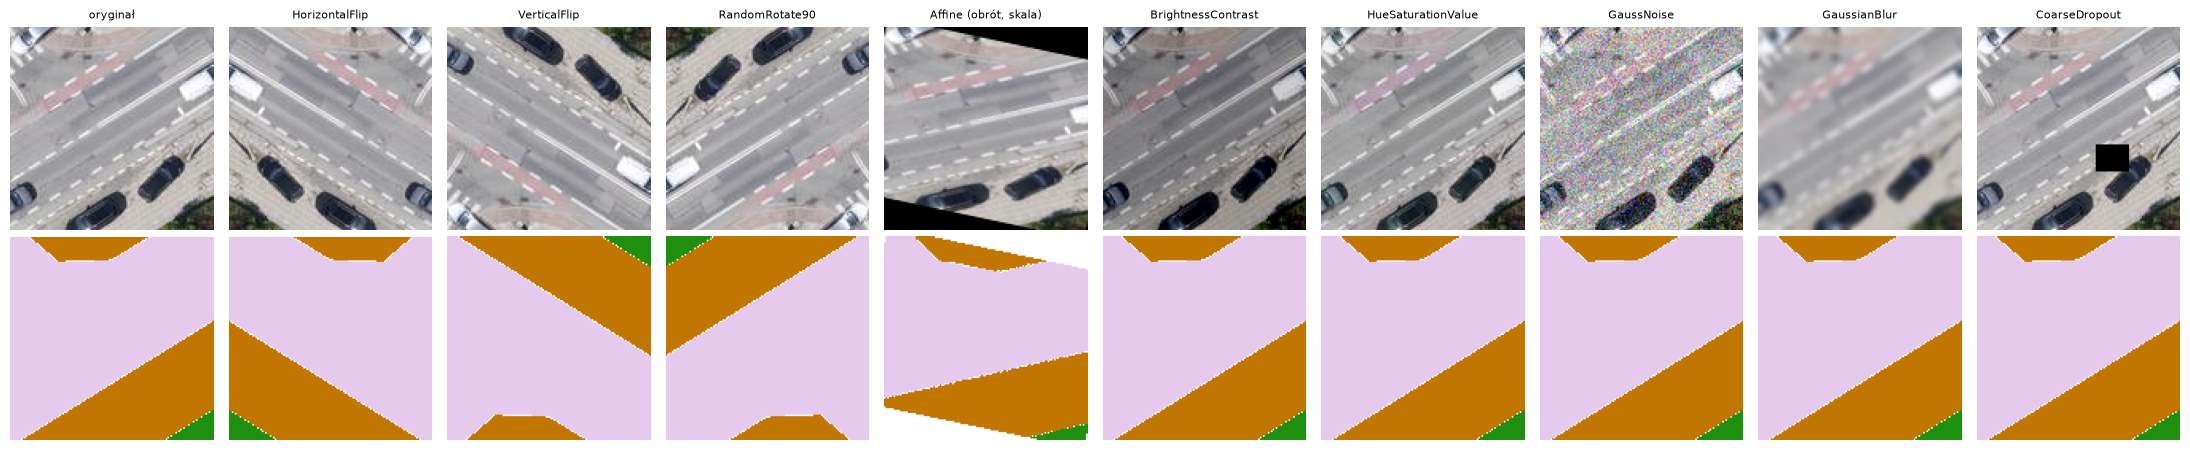

In [35]:
p0 = "6_5_lot1.png"
kafel = np.array(Image.open(BAZA / "images" / p0))
kafel_maska = np.array(Image.open(BAZA / "masks" / p0))

pojedyncze = {
    "oryginał": A.NoOp(),
    "HorizontalFlip": A.HorizontalFlip(p=1),
    "VerticalFlip": A.VerticalFlip(p=1),
    "RandomRotate90": A.RandomRotate90(p=1),
    "Affine (obrót, skala)": A.Affine(rotate=(-30, 30), scale=(0.8, 1.2), fill_mask=IGNORUJ, p=1),
    "BrightnessContrast": A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1),
    "HueSaturationValue": A.HueSaturationValue(p=1),
    "GaussNoise": A.GaussNoise(std_range=(0.05, 0.15), p=1),
    "GaussianBlur": A.GaussianBlur(blur_limit=(5, 7), p=1),
    "CoarseDropout": A.CoarseDropout(p=1),
}

fig, axes = plt.subplots(2, len(pojedyncze), figsize=(2.2 * len(pojedyncze), 4.6))
for i, (nazwa, t) in enumerate(pojedyncze.items()):
    wynik = t(image=kafel, mask=kafel_maska)            # obraz i maska razem
    axes[0, i].imshow(wynik["image"]); axes[0, i].set_title(nazwa, fontsize=8)
    axes[1, i].imshow(koloruj(wynik["mask"]))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

Przekształcenia geometryczne zmieniły maskę razem z obrazem, fotometryczne zostawiły ją bez zmian. Po obrocie (`Affine`) w rogach powstają puste miejsca: w obrazie wypełnia je czerń, a w masce wartość `IGNORUJ` (parametr `fill_mask`), żeby sieć nie uczyła się na nieistniejących etykietach.

### Które augmentacje mają sens?

Augmentacja ma tworzyć obrazy, **które mogłyby wystąpić w rzeczywistości**:

| Dane | Sensowne | Ryzykowne |
| --- | --- | --- |
| zdjęcia lotnicze i satelitarne (nadir) | odbicia w obu osiach, obroty o 90°, dowolny obrót | silna zmiana barw, jeśli kolor rozróżnia klasy (trawa a grunt) |
| zdjęcia naziemne, MNIST | odbicie poziome, małe obroty | odbicie pionowe; dla cyfr każde odbicie (6 ↔ 9) |
| SAR (projekt) | przesunięcia, niewielki szum | obroty i odbicia zmieniają geometrię oświetlenia i cienia radarowego |

### Potok augmentacji

`A.Compose` łączy przekształcenia; każde ma prawdopodobieństwo `p`. Ten sam kafel daje za każdym razem inny wynik.

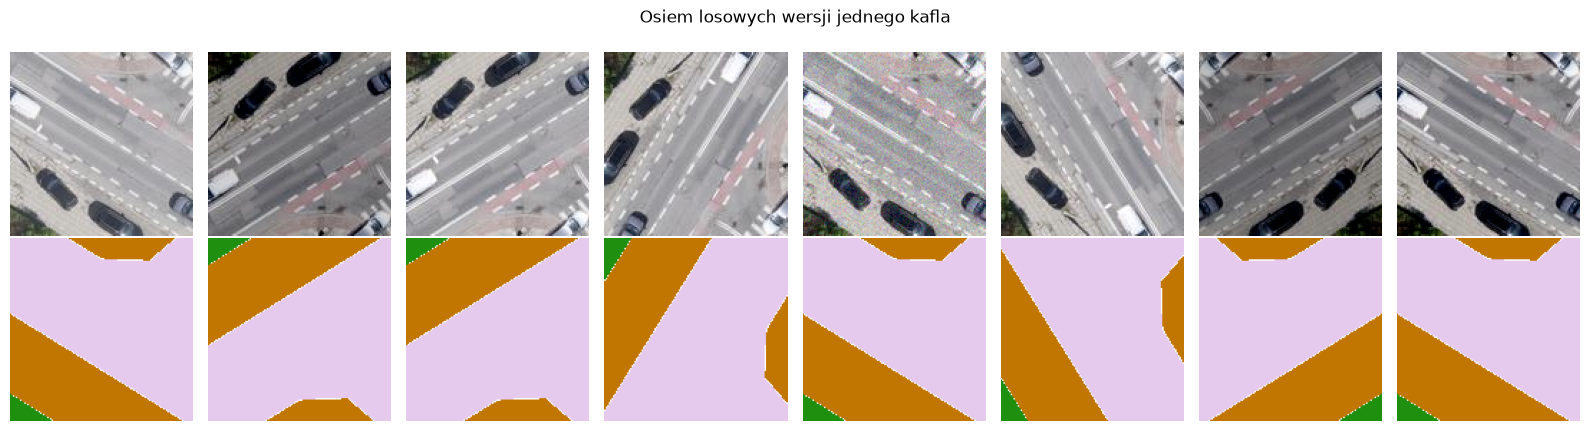

In [36]:
augmentacja = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.3),
])

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    wynik = augmentacja(image=kafel, mask=kafel_maska)
    axes[0, i].imshow(wynik["image"]); axes[1, i].imshow(koloruj(wynik["mask"]))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("Osiem losowych wersji jednego kafla"); plt.tight_layout(); plt.show()

## 6. Zadanie końcowe - pocięcie sceny SAR ICEYE na kafle

Plik `dane/ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK.tif` to zobrazowanie radarowe (SAR) z satelity ICEYE-X52: tryb spotlight, pasmo X, polaryzacja VV, produkt poglądowy (QLK) 4096×4096 px, 8 bitów, jeden kanał. Z obrazami SAR będziecie pracować w projekcie.

Przygotuj scenę tak, jak przed etykietowaniem i detekcją obiektów: **kafle 640×640, pokrycie 100 px**.

1. Funkcją `potnij_scene` wygeneruj trzy produkty w katalogu `kafle/`. Ile kafli powstało? Ile kolumn i wierszy ma siatka?
2. Wyświetl obraz z naniesionymi kaflami (`num_tiles_...png`) oraz trzy wybrane kafle: jeden z zabudową, jeden z rzeką, jeden z brzegu sceny. Podaj ich indeksy.
3. **Kontrola:** złóż scenę z powrotem z zapisanych kafli na podstawie `indeks.csv` i sprawdź, czy jest identyczna z `8bit_nogeoref_...png`.
4. Powtórz cięcie z `brzegi="odrzuc"` (do katalogu `kafle_odrzuc/`). Ile kafli powstało? Jaka część powierzchni sceny nie trafiła do żadnego kafla?
5. Odpowiedz na pytania:
   - Dla których kafli (wariant z dosunięciem) pozycja obliczona z samego indeksu, `x0 = (col_idx - 1) * (tile_size - overlap)`, różni się od rzeczywistej? O ile pikseli? Co by się stało z detekcjami z tych kafli, gdyby program odtwarzał pozycję w ten sposób?
   - Porównaj histogram sceny SAR z histogramem zdjęcia lotniczego `lot1.tif`. Jak przygotowałbyś te dane do sieci?
   - Które augmentacje z punktu 5 zastosowałbyś do kafli SAR, a które nie? Dlaczego?

Przy scenach rzędu 30 000×30 000 px nie wczytuje się całego rastra do pamięci, tylko czyta kolejne okna: `src.read(1, window=Window(x0, y0, szer, wys))`.

In [37]:
SCENA = DANE / "ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK.tif"
TILE_SIZE, OVERLAP = 640, 100

kat, indeks = potnij_scene(SCENA, "kafle", TILE_SIZE, OVERLAP)
print(f"kolumn: {indeks.col_idx.max()} | wierszy: {indeks.row_idx.max()}")
for p in sorted(kat.iterdir()):
    print("  ", p.name)
indeks.head()

ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK: scena 4096x4096, zapisano 64 kafli 640x640 (pokrycie 100) -> kafle\ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK
kolumn: 8 | wierszy: 8
   8bit_nogeoref_ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK.png
   indeks.csv
   num_tiles_ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK.png
   tiles


,col_idx,row_idx,x0,y0,read_w,read_h,out_name,srednia
0,1,1,0,0,640,640,1_1_ICEYE_U3QCNH_20260817T232958Z_10333016_X52...,42.53
1,2,1,540,0,640,640,2_1_ICEYE_U3QCNH_20260817T232958Z_10333016_X52...,43.61
2,3,1,1080,0,640,640,3_1_ICEYE_U3QCNH_20260817T232958Z_10333016_X52...,39.54
3,4,1,1620,0,640,640,4_1_ICEYE_U3QCNH_20260817T232958Z_10333016_X52...,45.70
4,5,1,2160,0,640,640,5_1_ICEYE_U3QCNH_20260817T232958Z_10333016_X52...,67.34


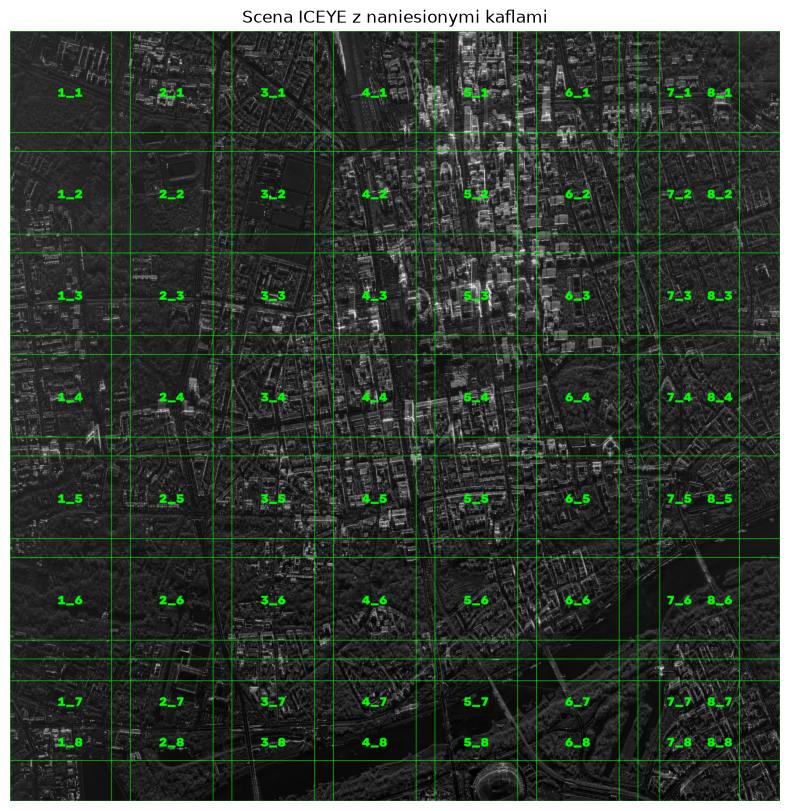

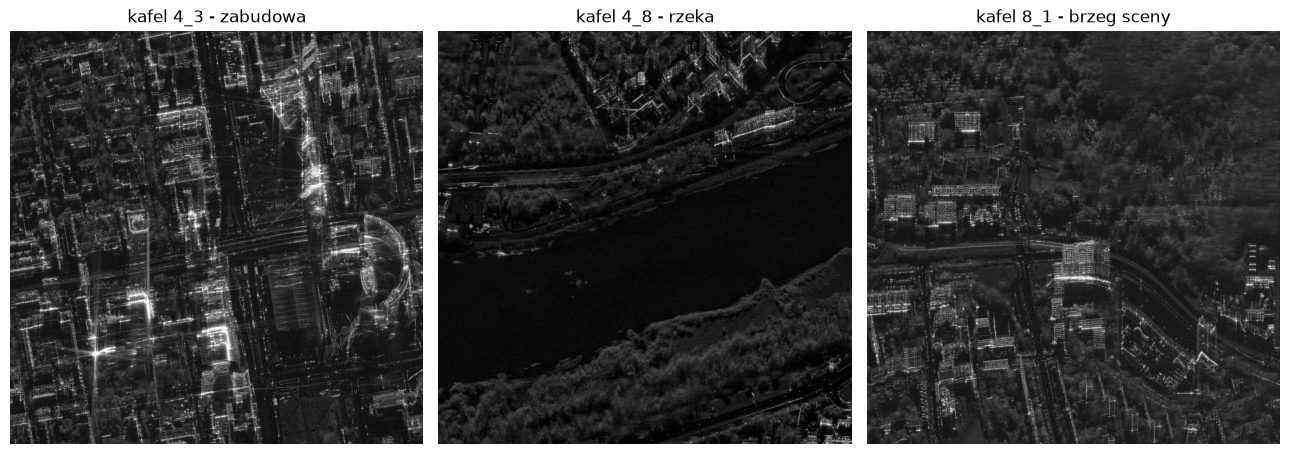

In [111]:
plt.figure(figsize=(10, 10))
plt.imshow(Image.open(kat / f"num_tiles_{SCENA.stem}.png")); plt.axis("off"); plt.title("Scena ICEYE z naniesionymi kaflami")
plt.show()

przyklady = {"4_3": "zabudowa", "4_8": "rzeka", "8_1": "brzeg sceny"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (p, opis) in zip(axes, przyklady.items()):
    ax.imshow(Image.open(kat / "tiles" / f"{p}_{SCENA.stem}.png"), cmap="gray"); ax.set_title(f"kafel {p} - {opis}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [38]:
scena8 = np.array(Image.open(kat / f"8bit_nogeoref_{SCENA.stem}.png"))
mozaika = np.zeros_like(scena8)
for w in pd.read_csv(kat / "indeks.csv").itertuples():
    kafel = np.array(Image.open(kat / "tiles" / w.out_name))
    mozaika[w.y0:w.y0 + w.read_h, w.x0:w.x0 + w.read_w] = kafel[:w.read_h, :w.read_w]
print("mozaika identyczna ze sceną:", np.array_equal(mozaika, scena8))

mozaika identyczna ze sceną: True


In [39]:
kat_o, indeks_o = potnij_scene(SCENA, "kafle_odrzuc", TILE_SIZE, OVERLAP, brzegi="odrzuc")
pokryte = np.zeros(scena8.shape, dtype=bool)
for w in indeks_o.itertuples():
    pokryte[w.y0:w.y0 + TILE_SIZE, w.x0:w.x0 + TILE_SIZE] = True
print(f"kafli: {len(indeks_o)} | poza kaflami: {1 - pokryte.mean():.1%} powierzchni sceny")

ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK: scena 4096x4096, zapisano 49 kafli 640x640 (pokrycie 100) -> kafle_odrzuc\ICEYE_U3QCNH_20260817T232958Z_10333016_X52_SLEDP_QLK
kafli: 49 | poza kaflami: 10.3% powierzchni sceny


## Podsumowanie

| Etap | Najczęstszy błąd |
| --- | --- |
| dopasowanie obrazu i referencji | przesunięcie o kilka pikseli, którego nikt nie sprawdził wizualnie |
| maska klas | interpolacja lub JPEG tworzą nieistniejące klasy |
| cięcie | utrata brzegów obrazu, obiekty przecięte granicą kafla (brak pokrycia), pozycja kafla odtwarzana z indeksu zamiast zapisana |
| podział | losowy podział nakładających się kafli (wyciek danych) |
| augmentacja | obraz przekształcony, maska nie; augmentacja na walidacji i teście |